# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('../data/airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [2]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

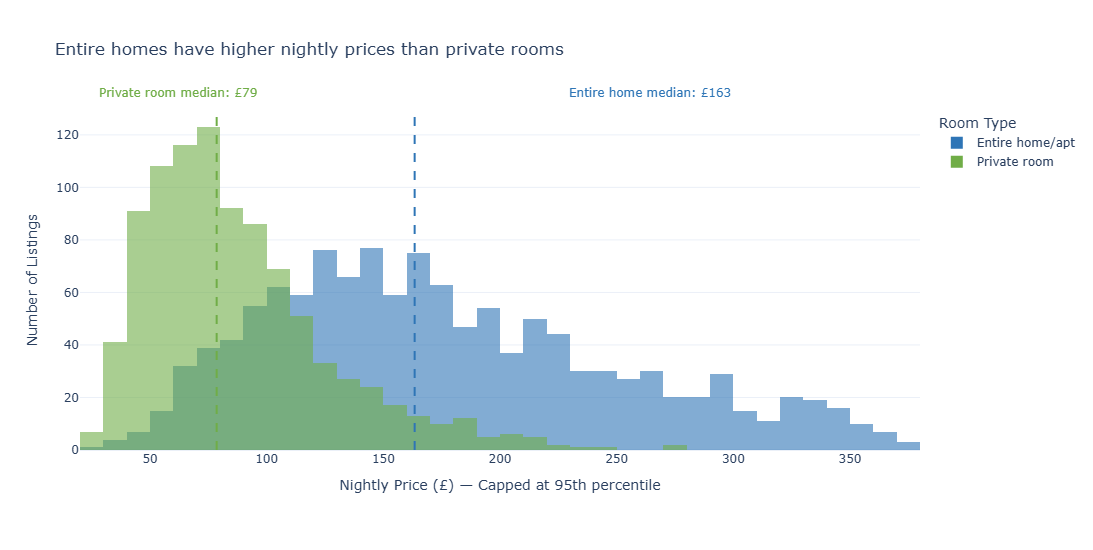

In [7]:


# Keep only Entire home/apt and Private room
hist_df = df_cap[
    df_cap['room_type'].isin(['Entire home/apt', 'Private room'])
].copy()

# Calculate median for each room type
medians = hist_df.groupby('room_type')['price'].median()

# Create overlapping histogram
fig = px.histogram(
    hist_df,
    x='price',
    color='room_type',
    nbins=50,
    barmode='overlay',
    opacity=0.6,
    color_discrete_map={
        'Entire home/apt': '#2E75B6',
        'Private room': '#70AD47'
    },
    labels={
        'price': 'Nightly Price (£)',
        'count': 'Number of Listings'
    },
    template='plotly_white',
    height=550
)


# Add median reference lines without overlapping labels
fig.add_vline(
    x=medians['Entire home/apt'],
    line_dash='dash',
    line_color='#2E75B6'
)

fig.add_vline(
    x=medians['Private room'],
    line_dash='dash',
    line_color='#70AD47'
)

# Place labels separately above the chart
fig.add_annotation(
    x=0.02, y=1.08,
    xref='paper', yref='paper',
    text=f"Private room median: £{medians['Private room']:.0f}",
    showarrow=False,
    xanchor='left',
    font=dict(color='#70AD47')
)

fig.add_annotation(
    x=0.58, y=1.08,
    xref='paper', yref='paper',
    text=f"Entire home median: £{medians['Entire home/apt']:.0f}",
    showarrow=False,
    xanchor='left',
    font=dict(color='#2E75B6')
)

fig.update_layout(margin=dict(t=110, b=100))

fig.update_layout(
    title='Entire homes have higher nightly prices than private rooms',
    xaxis_title='Nightly Price (£) — Capped at 95th percentile',
    yaxis_title='Number of Listings',
    legend_title='Room Type',
    template='plotly_white'
)

fig.show()

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out with before plotting

Two busiest boroughs: ['Tower Hamlets', 'Hackney']


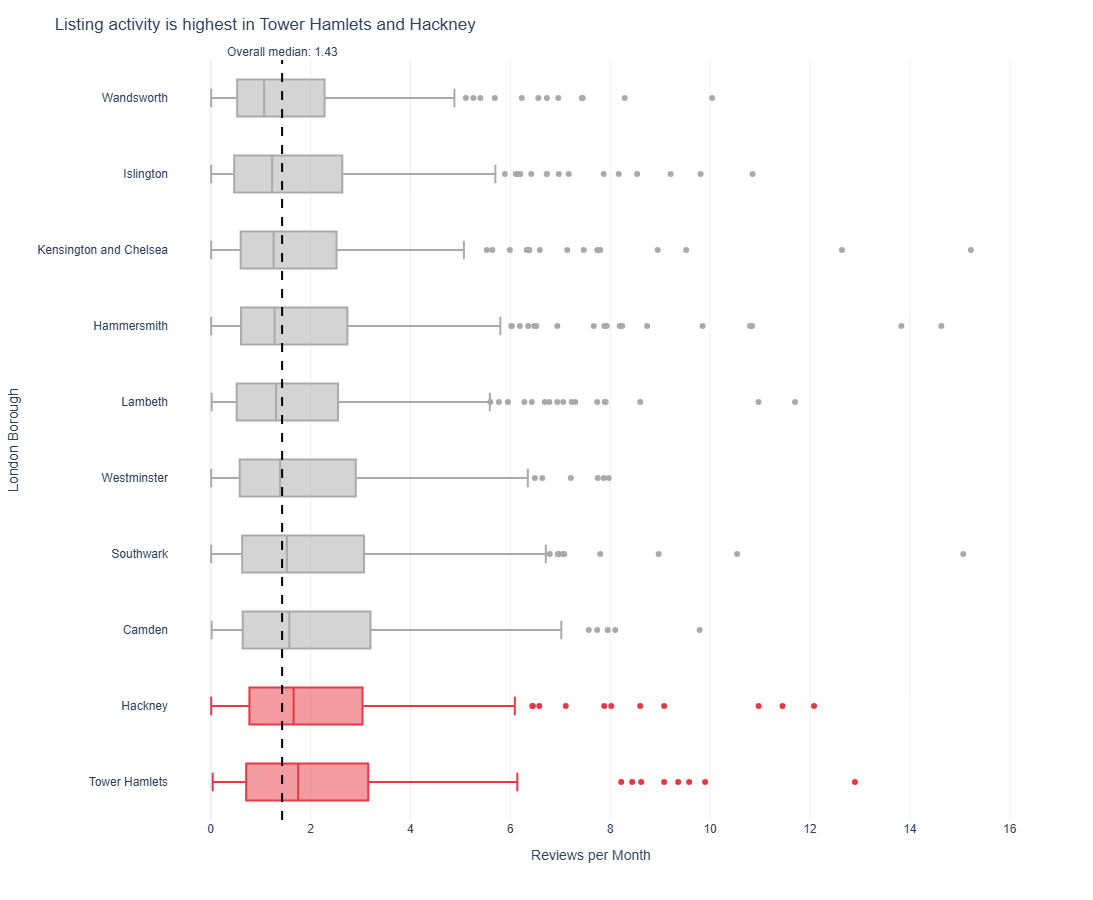

In [8]:

# Task 2 — Box plot: listing activity by borough

# Remove listings with zero or missing reviews per month
activity_df = df[
    (df['reviews_per_month'] > 0) &
    (df['reviews_per_month'].notna()) &
    (df['neighbourhood'].notna())
].copy()

# Calculate median reviews per month for each borough
borough_medians = (
    activity_df.groupby('neighbourhood')['reviews_per_month']
    .median()
    .sort_values(ascending=False)
)

# Identify the two most active boroughs
top_two = borough_medians.head(2).index.tolist()

print("Two busiest boroughs:", top_two)

# Sort boroughs by median activity
borough_order = borough_medians.sort_values(ascending=True).index.tolist()

# Highlight the two busiest boroughs in red
colour_map = {
    borough: ('#E63946' if borough in top_two else '#AAAAAA')
    for borough in borough_order
}

# Create horizontal box plot
fig = px.box(
    activity_df,
    x='reviews_per_month',
    y='neighbourhood',
    color='neighbourhood',
    orientation='h',
    category_orders={'neighbourhood': borough_order},
    color_discrete_map=colour_map,
    points='outliers',
    labels={
        'reviews_per_month': 'Reviews per Month',
        'neighbourhood': 'London Borough'
    },
    height=900,
    template='plotly_white'
)

# Calculate overall median
overall_median = activity_df['reviews_per_month'].median()

# Add overall median reference line
fig.add_vline(
    x=overall_median,
    line_dash='dash',
    line_color='black',
    annotation_text=f'Overall median: {overall_median:.2f}',
    annotation_position='top'
)

# Add chart title and formatting
fig.update_layout(
    title=f"Listing activity is highest in {top_two[0]} and {top_two[1]}",
    xaxis_title='Reviews per Month',
    yaxis_title='London Borough',
    font=dict(family='Arial', size=12),
    showlegend=False
)

fig.show()
